# European option pricing

1. Closed-form Black-Scholes-Merton price (benchmark)
2. Monte Carlo estimator

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

from src.european import bs_price

In [2]:
# Same parameters as the GBM notebook
S0, K, r, q, sigma, T = 100.0, 100.0, 0.05, 0.02, 0.20, 1.0

In [3]:
call = bs_price(S0, K, r, q, sigma, T, "call")
put = bs_price(S0, K, r, q, sigma, T, "put")

print(f"European call : {call:.4f}")
print(f"European put  : {put:.4f}")

European call : 9.2270
European put  : 6.3301


In [4]:
# Put-call parity: C - P = S0 e^{-qT} - K e^{-rT}
lhs = call - put
rhs = S0 * np.exp(-q * T) - K * np.exp(-r * T)

print(f"C - P                  : {lhs:.6f}")
print(f"S0 e^-qT - K e^-rT     : {rhs:.6f}")
print(f" Parity hols           :", np.isclose(lhs, rhs))

C - P                  : 2.896925
S0 e^-qT - K e^-rT     : 2.896925
 Parity hols           : True


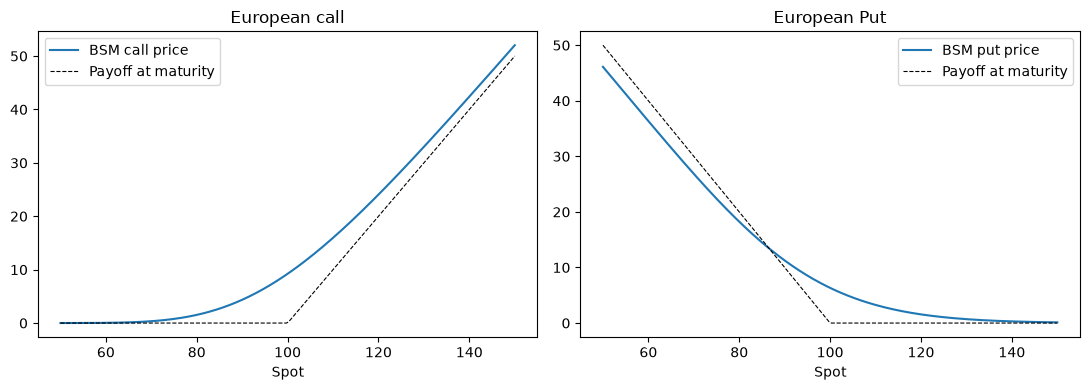

In [5]:
spots = np.linspace(50, 150, 200)
calls = bs_price(spots, K, r, q, sigma, T, "call")
puts = bs_price(spots, K, r, q, sigma, T, "put")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(spots, calls, label="BSM call price")
ax[0].plot(spots, np.maximum(spots - K, 0), "k--", lw=0.8, label="Payoff at maturity")
ax[0].set_title("European call")
ax[0].set_xlabel("Spot")
ax[0].legend()

ax[1].plot(spots, puts, label="BSM put price")
ax[1].plot(spots, np.maximum(K - spots, 0), "k--", lw=0.8, label="Payoff at maturity")
ax[1].set_title("European Put")
ax[1].set_xlabel("Spot")
ax[1].legend()

plt.tight_layout()
plt.savefig("../figures/european_bsm_prices.png", dpi=150)
plt.show()

## Monte Carlo estimator

$V \approx e^{-rT} \frac{1}{N}\sum_i \text{payoff}(S_T^{(i)})$, with a 95% confidence interval from the sample standard error.

In [6]:
from src.rng import LCG
from src.european import mc_european

n_paths = 100_000
res_call = mc_european(S0, K, r, q, sigma, T, n_paths, LCG(seed=42), "call")
res_put = mc_european(S0, K, r, q, sigma, T, n_paths, LCG(seed=43), "put")

for name, res, ref in [("call", res_call, call), ("put", res_put, put)]:
    inside = res["ci_low"] <= ref <= res["ci_high"]
    print(f"{name:4s} | MC {res['price']:.4f} (se {res['std_error']:.4f}) "
          f"| CI [{res['ci_low']:.4f}, {res['ci_high']:.4f}] "
          f"| BSM {ref:.4f} | inside CI: {inside}")

call | MC 9.2590 (se 0.0438) | CI [9.1732, 9.3448] | BSM 9.2270 | inside CI: True
put  | MC 6.3063 (se 0.0289) | CI [6.2495, 6.3630] | BSM 6.3301 | inside CI: True


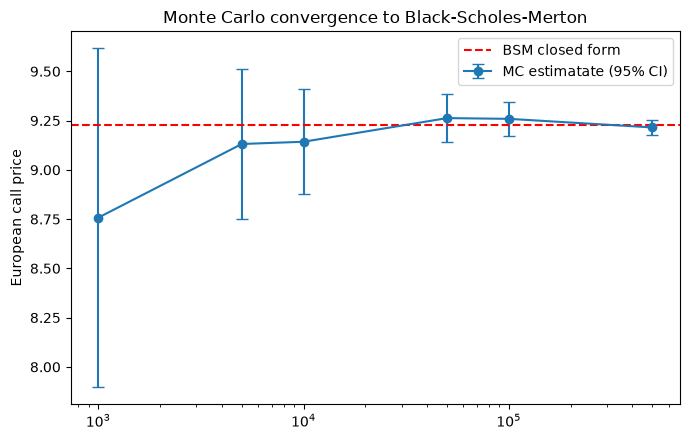

Std error ratio N= 1,000 vs N=100,000 : 10.0 (theory: 10)


In [7]:
Ns = [1_000, 5_000, 10_000, 50_000, 100_000, 500_000]
prices, ses = [], []
for N in Ns:
    res = mc_european(S0, K, r, q, sigma, T, N, LCG(seed=42), "call")
    prices.append(res["price"])
    ses.append(res["std_error"])

prices, ses = np.array(prices), np.array(ses)

plt.figure(figsize=(7, 4.5))
plt.errorbar(Ns, prices, yerr=1.96 * ses, fmt="o-", capsize=4, label="MC estimatate (95% CI)")
plt.axhline(call, color="red", linestyle="--", label="BSM closed form")
plt.xscale("log")
plt.ylabel("European call price")
plt.title("Monte Carlo convergence to Black-Scholes-Merton")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/european_mc_convergence.png", dpi=150)
plt.show()

print("Std error ratio N= 1,000 vs N=100,000 :", round(ses[0] / ses[4], 1), "(theory: 10)")